# Звук под лупой: частота и громкость

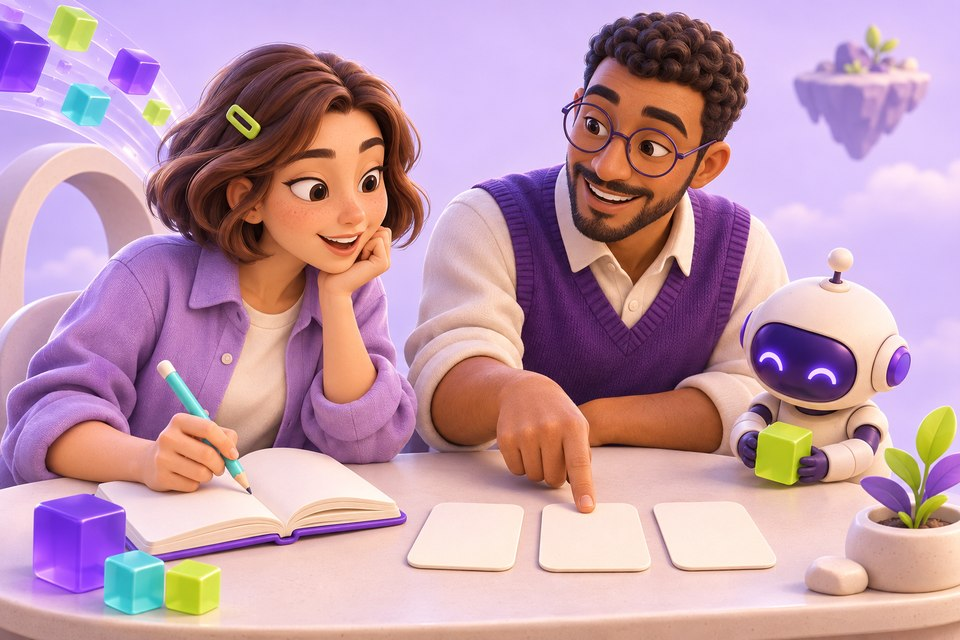

**Увидим, из каких тонов состоит волна.**

**Твой результат:** Восстановить частоты и амплитуды двух тонов и сравнить настоящее квантование.

**Что разбираем:** Основы дискретного сигнала и FFT; внешнее аудио и трафик из архива не требуются.

**Данные:** Сумма двух синусоид, созданная формулой.

**Перед началом:**

- Python 3 и указанные библиотеки
- Запускай три шага сверху вниз

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. Сложи два чистых тона
2. Найди частоты в спектре
3. Округли амплитуду по ступенькам

Затем — твой небольшой эксперимент. Проходи ячейки сверху вниз.

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt


<a id="step-1"></a>

## 1. Сложи два чистых тона

Частота дискретизации задаёт число измерений за секунду. Время строим без повторного включения правой границы.

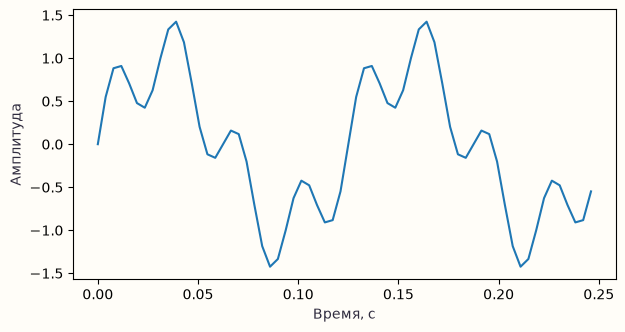

In [2]:
fs = 256
N = 512
t = np.arange(N) / fs
signal = np.sin(2 * np.pi * 8 * t) + 0.5 * np.sin(2 * np.pi * 32 * t)
assert len(signal) == N
assert np.isclose(t[1] - t[0], 1 / fs)
plt.plot(t[:64], signal[:64])
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.show()


**Что проверить:** Волна меняется сложнее, чем одиночная синусоида.

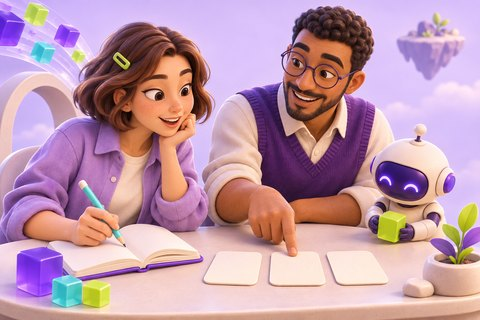

> **Мира:** Почему N не равно fs?

> **Данил:** fs — измерений в секунду, N — всего измерений. Здесь запись длится две секунды.

> **Пикс:** Проверь длительность N / fs.

<a id="step-2"></a>

## 2. Найди частоты в спектре

FFT показывает вклад каждой частоты. Нормируем на длину записи, а частотную ось считаем в герцах.

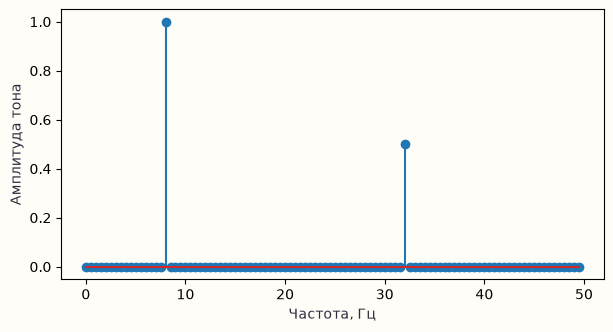

Два тона, Гц: [ 8. 32.]


In [3]:
frequencies = np.fft.rfftfreq(N, d=1 / fs)
amplitude = np.abs(np.fft.rfft(signal)) / N
amplitude[1:-1] *= 2
peaks = np.argsort(amplitude)[-2:]
assert set(frequencies[peaks]) == {8.0, 32.0}
assert np.isclose(amplitude[frequencies == 8][0], 1.0)
assert np.isclose(amplitude[frequencies == 32][0], 0.5)
plt.stem(frequencies[:100], amplitude[:100])
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда тона')
plt.show()
print('Два тона, Гц:', np.sort(frequencies[peaks]))


**Что проверить:** Пики стоят на 8 и 32 Гц; их высоты соответствуют исходным амплитудам.

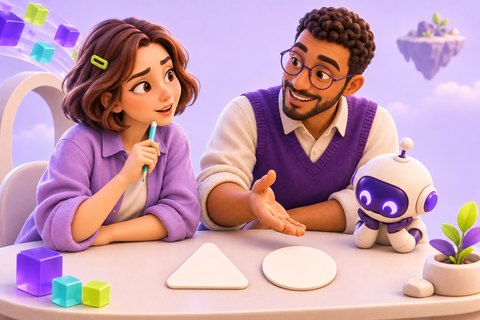

> **Мира:** Почему делим на N, а не на частоту дискретизации?

> **Данил:** Размер преобразования равен числу отсчётов. Иначе громкость изменялась бы просто от длительности записи.

> **Пикс:** Измени N на 1024 и проверь высоты пиков.

<a id="step-3"></a>

## 3. Округли амплитуду по ступенькам

Квантование действительно округляет значения. Ступенчатый стиль линии сам по себе этого не делает.

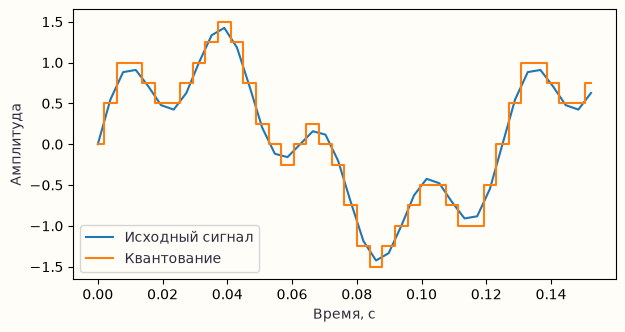

Максимальная ошибка округления: 0.123


In [4]:
quantum = 0.25
quantized = np.round(signal / quantum) * quantum
error = np.abs(quantized - signal)
assert np.allclose(quantized / quantum, np.round(quantized / quantum))
assert error.max() <= quantum / 2 + 1e-12
plt.plot(t[:40], signal[:40], label='Исходный сигнал')
plt.step(t[:40], quantized[:40], where='mid', label='Квантование')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.legend()
plt.show()
print('Максимальная ошибка округления:', round(error.max(), 3))


**Что проверить:** Ступени состоят из кратных 0.25 значений, ошибка не больше половины шага.

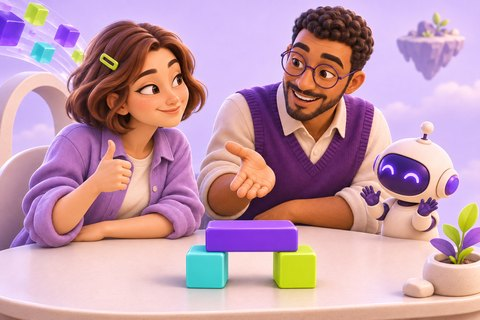

> **Мира:** То есть plt.step ещё не превращает звук в цифровые уровни?

> **Данил:** Да. Сначала округляем числа, потом выбираем способ их показать.

> **Пикс:** Найди round в расчёте quantized: это и есть квантование.

<a id="your-experiment"></a>

## Попробуй сам

Уменьши шаг квантования вдвое.

**Где изменить:** quantum в третьем шаге.

**Как проверить:** Максимальная допустимая ошибка тоже уменьшается вдвое.

## Что теперь умеешь

- Герцы и число отсчётов — разные величины.
- Квантование изменяет данные, а не только рисунок.

## Границы этого примера

- Два идеальных тона; не анализ реального шумного аудио.
- Формула удвоения внутренних FFT-бинов здесь рассчитана на чётное N.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/AudioNet/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%9E%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D1%81%D0%B8%D0%B3%D0%BD%D0%B0%D0%BB%D0%BE%D0%B2%22%22.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%9E%D0%B1%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%BA%D0%B0_%D1%81%D0%B8%D0%B3%D0%BD%D0%B0%D0%BB%D0%BE%D0%B2%22%22.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 14 (от 0).** Нормировка FFT использует частоту дискретизации вместо длины записи. → Используются len(signal) и rfftfreq.

Проверка: Проверяются амплитуды 1 и 0.5.

Фрагмент исходника: <code>N=sr; fft(y)/N</code>

---

**Ошибка · исходная ячейка 9 (от 0).** Квантованный график рисует неокруглённый сигнал. → Добавлено округление с явным шагом.

Проверка: Ошибка не превышает quantum/2.

Фрагмент исходника: <code>plt.step(t, x)</code>

---

**Ошибка · исходная ячейка 9 (от 0).** Старый параметр stem несовместим с современным Matplotlib. → Вызов stem без удалённого параметра.

Проверка: График строится в центральном прогоне.

Фрагмент исходника: <code>use_line_collection=True</code>

</details>